# 01 · Limpieza y exploración

Entrada: `data/autos_raw.csv` (17.095 avisos, corrida del 2026-10-28).
Salida: `data/autos_clean.csv` y `data/limpieza_reglas.csv` (cuántas filas saca cada regla).

Decisiones:

1. Precios en pesos → dólares con la cotización BCU del día del scraping (40,096 pesos por dólar).
2. Se sacan los **0 km**: `km ≤ 1` y año ≥ 2025.
3. Un auto de 2024 o anterior con **menos de 1.000 km** no es creíble: son km sin informar
   (0 o 1) o km cargados en miles (100, 150, 200 = 100.000, 150.000, 200.000). Se saca.
4. **Km de relleno**: 999.999 o más (9.999.999, 1.000.000…) o todos los dígitos iguales
   (1.111, 11.111, 111.111, 999.999…). Solo 111.111 aparece 89 veces, incluso en autos 2026.
5. **Año mal cargado**: año ≥ 2026 con más de 100.000 km (ej.: Daihatsu Cuore "2027" con 240.000 km).
6. Precio mayor a **USD 150.000** = outlier, se saca.
7. **Avisos en pesos que convertidos dan menos de USD 3.000**: se sacan. En el notebook 03, 10 de los
   20 residuos más negativos eran avisos en pesos (1,4 % del total): cuotas, entregas iniciales o
   dólares marcados como pesos (ej.: Hilux SW4 2018 a 47.500 pesos).
8. **Precio menor a USD 1.000** (en cualquier moneda): seña o error de carga.
9. **Avisos de compra** ("Compro autos"): no venden un auto, se sacan.
10. **Gemelos** (misma marca, modelo, año, km, precio y moneda) comparten `grupo_gemelo`:
    el split train/test y el K-fold se hacen agrupando por esa columna (notebook de modelos).

La agrupación de modelos raros **no** se hace acá: depende de los conteos de train,
así que va después del split.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
FIGS = Path("figuras")
FIGS.mkdir(exist_ok=True)

# Paleta (categórica en orden fijo) y estilo sobrio para el informe
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
TINTA, TINTA_2, GRILLA = "#1f1f1e", "#5f5e58", "#e4e3dd"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "lines.linewidth": 2, "font.size": 10,
})

raw = pd.read_csv(DATA / "autos_raw.csv")
raw.shape

(17095, 21)

## 1. Chequeos de entrada

In [2]:
assert raw["item_id"].is_unique, "item_id repetido: el scraper ya deduplicaba"
claves = ["marca", "modelo", "anio", "km", "precio", "moneda"]
print("Nulos en columnas clave:")
print(raw[claves].isna().sum())
print()
print(raw["moneda"].value_counts())

Nulos en columnas clave:
marca       0
modelo    156
anio        0
km          0
precio      0
moneda      0
dtype: int64

moneda
USD    16848
UYU      247
Name: count, dtype: int64


## 2. Gemelos

Un gemelo es el mismo auto publicado más de una vez (mismas seis columnas clave).
El grupo se calcula **sobre los datos crudos**, antes de sacar filas, y viaja con cada aviso
hasta el notebook de modelos.

In [3]:
df = raw.copy()
df["grupo_gemelo"] = df.groupby(claves, sort=False, dropna=False).ngroup()  # dropna=False: 156 avisos sin modelo
tam = df.groupby("grupo_gemelo")["item_id"].transform("size")
print(f"Filas con al menos un gemelo: {(tam > 1).sum()}")
print(f"Grupos con más de una fila:   {df.loc[tam > 1, 'grupo_gemelo'].nunique()}")
print(f"Tamaño máximo de grupo:       {tam.max()}")
assert df["grupo_gemelo"].ge(0).all(), "hay avisos sin grupo"

Filas con al menos un gemelo: 406
Grupos con más de una fila:   202
Tamaño máximo de grupo:       3


## 3. Moneda

Cotización BCU del **28/10/2026**, fecha del scraping: dólar billete, 40,096 pesos por dólar.
Fuente: bcu.gub.uy → Estadísticas e indicadores → Cotizaciones (consultado el 21/11/2026).

In [4]:
COTIZACION_BCU_2026_10_28 = 40.096  # pesos por dólar (BCU, dólar billete, 28/10/2026)

df["precio_usd"] = np.where(
    df["moneda"] == "UYU", df["precio"] / COTIZACION_BCU_2026_10_28, df["precio"]
)
print(df.loc[df["moneda"] == "UYU", "precio_usd"].describe().round(0))

count         247.0
mean       243642.0
std       2272672.0
min           499.0
25%          2444.0
50%          4240.0
75%          7707.0
max      24940144.0
Name: precio_usd, dtype: float64


## 4. Reglas de limpieza

Cada regla se aplica en orden y se registra cuántas filas saca. Ninguna regla se superpone
con otra sin quedar contada: una fila la saca la primera regla que la toma.

In [5]:
ANIO_SCRAPING = 2026


def km_repetido(km):
    """True si el km tiene 4 o más cifras y todas iguales (1.111, 11.111, 111.111, 999.999…)."""
    s = km.astype("int64").astype(str)
    return (s.str.len() >= 4) & s.str.fullmatch(r"(\d)\1+")


reglas = [
    ("0 km (km ≤ 1 y año ≥ 2025)",
     lambda d: (d["km"] <= 1) & (d["anio"] >= 2025)),
    ("km sin informar o en miles (km < 1.000 y año < 2025)",
     lambda d: (d["km"] < 1_000) & (d["anio"] < 2025)),
    ("km de relleno (≥ 999.999 o todos los dígitos iguales)",
     lambda d: (d["km"] >= 999_999) | km_repetido(d["km"])),
    (f"año mal cargado (año ≥ {ANIO_SCRAPING} y km > 100.000)",
     lambda d: (d["anio"] >= ANIO_SCRAPING) & (d["km"] > 100_000)),
    ("precio > USD 150.000",
     lambda d: d["precio_usd"] > 150_000),
    ("en pesos y < USD 3.000 (cuota o moneda mal cargada)",
     lambda d: (d["moneda"] == "UYU") & (d["precio_usd"] < 3_000)),
    ("precio < USD 1.000 (seña o error de carga)",
     lambda d: d["precio_usd"] < 1_000),
    ("aviso de compra (\"Compro\" en el título)",
     lambda d: d["titulo"].str.contains(r"\bcompro\b", case=False, regex=True)),
]

registro = [{"regla": "inicio", "sacadas": 0, "quedan": len(df)}]
limpio = df
for nombre, condicion in reglas:
    sacar = condicion(limpio)
    limpio = limpio.loc[~sacar]
    registro.append({"regla": nombre, "sacadas": int(sacar.sum()), "quedan": len(limpio)})

registro = pd.DataFrame(registro)
registro

,regla,sacadas,quedan
0,inicio,0,17095
1,0 km (km ≤ 1 y año ≥ 2025),49,17046
2,km sin informar o en miles (km < 1.000 y año <...,115,16931
3,km de relleno (≥ 999.999 o todos los dígitos i...,233,16698
4,año mal cargado (año ≥ 2026 y km > 100.000),4,16694
5,precio > USD 150.000,33,16661
6,en pesos y < USD 3.000 (cuota o moneda mal car...,75,16586
7,precio < USD 1.000 (seña o error de carga),2,16584
8,"aviso de compra (""Compro"" en el título)",3,16581


### Control: lo que queda en los extremos

Lo que queda entre 300.000 y 999.999 km es raro pero posible (taxis, utilitarios) y se mantiene.
Tampoco quedan años futuros con muchos km ni km imposibles para la edad del auto.

In [6]:
for umbral in [300_000, 500_000, 900_000]:
    print(f"km > {umbral:>9,}: {(limpio['km'] > umbral).sum():>4} avisos")
assert not km_repetido(limpio["km"]).any() and limpio["km"].lt(999_999).all()
assert limpio["precio_usd"].between(1_000, 150_000).all()
print(f"Año: {limpio['anio'].min()} a {limpio['anio'].max()} · km mínimo con año < 2025: "
      f"{limpio.loc[limpio['anio'] < 2025, 'km'].min():,}")
limpio.nlargest(8, "km")[["titulo", "anio", "km", "precio_usd"]]

km >   300,000:  451 avisos
km >   500,000:   58 avisos
km >   900,000:    0 avisos
Año: 1962 a 2027 · km mínimo con año < 2025: 1,000


,titulo,anio,km,precio_usd
14237,Volkswagen Parati 2005 1.9 Sd,2005,800000,5500.0
15111,Mercedes-Benz Sprinter 2017 2.1 415 Chasis 366...,2017,800000,23900.0
16766,Toyota Hiace 1997 2.4 Hiace 15 Pas,1997,800000,6000.0
16640,Mitsubishi L300 2001 Minivans,2001,780000,6500.0
6529,Toyota Hilux 2009 3.0 Tdi Sr Cab Doble 4x4 Dob...,2009,778000,25000.0
934,Citroën C-elysée 2020 1.6 Feel Hdi 92,2020,750000,5990.0
12321,Citroën C-elysée 2018 1.6 Feel Hdi 92,2018,750000,6490.0
16893,Studebaker Lark 2001 Sedán Cuatro Puertas,2001,750000,6000.0


## 5. Variables derivadas

In [7]:
ANIO_REF = pd.to_datetime(limpio["fecha_scraping"]).dt.year.max()  # 2026
assert ANIO_REF == ANIO_SCRAPING
limpio = limpio.assign(
    antiguedad=ANIO_REF - limpio["anio"],          # 2027 → -1 (año modelo adelantado)
    log_precio=np.log(limpio["precio_usd"]),
    log_km=np.log(limpio["km"]),
    tipo_vendedor=limpio["tipo_vendedor"].fillna("desconocido"),
    modelo=limpio["modelo"].fillna("sin_modelo"),  # con umbral 1 queda como categoría propia de cada marca
)
limpio[["antiguedad", "km", "precio_usd", "log_precio", "log_km"]].describe().round(2)

,antiguedad,km,precio_usd,log_precio,log_km
count,16581.00,16581.00,16581.00,16581.00,16581.00
mean,8.99,119241.72,16655.22,9.52,11.42
std,6.47,79765.93,13257.32,0.59,0.89
min,-1.00,2.00,1000.00,6.91,0.69
25%,4.00,65000.00,9200.00,9.13,11.08
50%,8.00,108000.00,12900.00,9.46,11.59
75%,12.00,155000.00,18900.00,9.85,11.95
max,64.00,800000.00,149990.00,11.92,13.59


## 6. Exploración

### 6.1 ¿Por qué log(precio)?

El precio tiene cola larga a la derecha: unos pocos autos caros dominan el error cuadrático.
En log la distribución es casi simétrica, y un coeficiente se lee como **variación porcentual**.

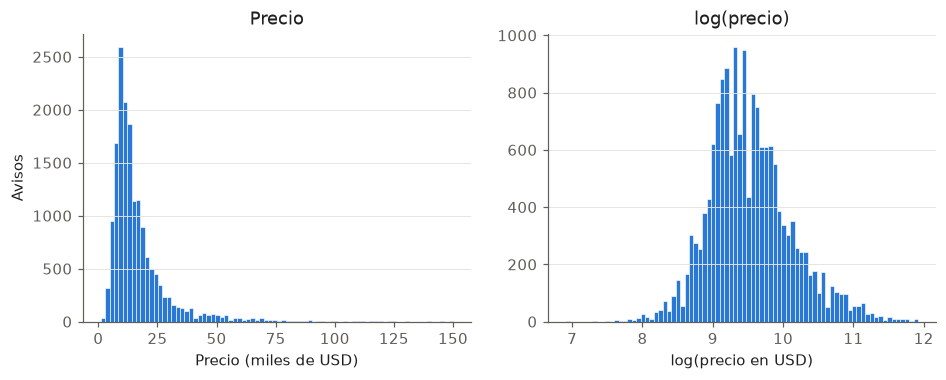

Asimetría precio: 3.45 · log(precio): 0.56


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(limpio["precio_usd"] / 1000, bins=80, color=SERIES[0], edgecolor="white", linewidth=0.4)
ax[0].set(xlabel="Precio (miles de USD)", ylabel="Avisos", title="Precio")
ax[1].hist(limpio["log_precio"], bins=80, color=SERIES[0], edgecolor="white", linewidth=0.4)
ax[1].set(xlabel="log(precio en USD)", title="log(precio)")
for a in ax: a.grid(axis="x", visible=False)
fig.savefig(FIGS / "01_precio_vs_log.png")
plt.show()
print(f"Asimetría precio: {limpio['precio_usd'].skew():.2f} · log(precio): {limpio['log_precio'].skew():.2f}")

### 6.2 Antigüedad y kilómetros

Si la relación con log(precio) es aproximadamente lineal, el modelo de la propuesta
(`log(precio) = β₀ + β₁·antigüedad + β₂·log(km) + …`) tiene sentido.

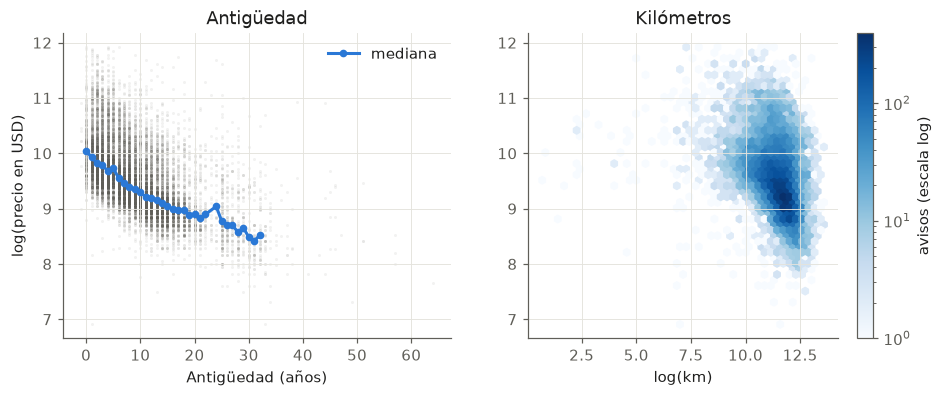

            log_precio  antiguedad  log_km
log_precio        1.00       -0.56   -0.39
antiguedad       -0.56        1.00    0.56
log_km           -0.39        0.56    1.00


In [9]:
med = limpio.groupby("antiguedad")["log_precio"].agg(["median", "size"])
med = med[med["size"] >= 30]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(limpio["antiguedad"], limpio["log_precio"], s=4, alpha=0.08, color=TINTA_2, linewidths=0)
ax[0].plot(med.index, med["median"], color=SERIES[0], marker="o", markersize=4, label="mediana")
ax[0].set(xlabel="Antigüedad (años)", ylabel="log(precio en USD)", title="Antigüedad")
ax[0].legend(frameon=False)
hb = ax[1].hexbin(limpio["log_km"], limpio["log_precio"], gridsize=45, cmap="Blues", mincnt=1, bins="log")
ax[1].set(xlabel="log(km)", title="Kilómetros")
fig.colorbar(hb, ax=ax[1], label="avisos (escala log)")
fig.savefig(FIGS / "02_antiguedad_km.png")
plt.show()
print(limpio[["log_precio", "antiguedad", "log_km"]].corr().round(2))

### 6.3 ¿La depreciación es igual en todas las marcas? (pregunta secundaria)

Mediana del precio por antigüedad para las 6 marcas con más avisos, en escala log:
**pendientes paralelas** = misma depreciación porcentual; pendientes distintas = la marca importa.

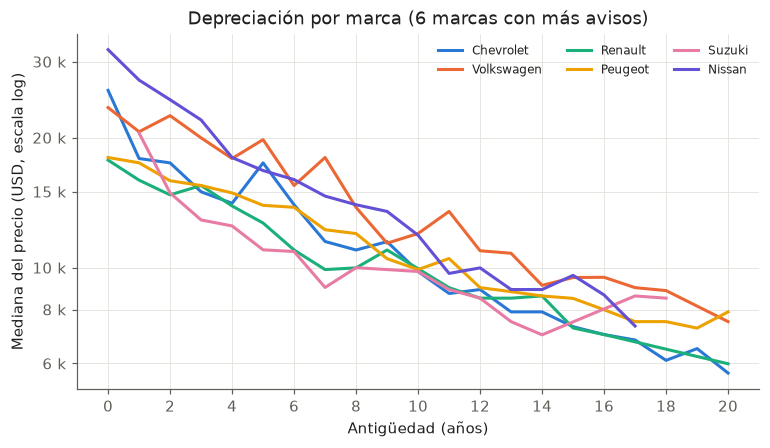

,marca,avisos,pierde_por_año_%
0,Chevrolet,2108,6.6
1,Volkswagen,2005,5.8
2,Renault,1254,5.0
3,Peugeot,1186,5.6
4,Suzuki,1084,4.8
5,Nissan,988,7.5


In [10]:
top = limpio["marca"].value_counts().head(6).index
fig, ax = plt.subplots(figsize=(8, 4.2))
for color, marca in zip(SERIES, top):
    m = (limpio[limpio["marca"] == marca]
         .groupby("antiguedad")["precio_usd"].agg(["median", "size"]))
    m = m[(m["size"] >= 15) & (m.index >= 0) & (m.index <= 20)]
    ax.plot(m.index, m["median"], color=color, label=marca)
ax.set_yscale("log")
ticks = [6000, 8000, 10000, 15000, 20000, 30000]
ax.yaxis.set_major_locator(plt.FixedLocator(ticks))
ax.yaxis.set_minor_locator(plt.NullLocator())
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f} k"))
ax.set_xticks(range(0, 21, 2))
ax.set(xlabel="Antigüedad (años)", ylabel="Mediana del precio (USD, escala log)",
       title="Depreciación por marca (6 marcas con más avisos)")
ax.legend(frameon=False, ncol=3, fontsize=8)
fig.savefig(FIGS / "03_depreciacion_marca.png")
plt.show()

# Pendiente por marca: log(precio) ~ antigüedad, ajuste simple (exploratorio)
filas = []
for marca in top:
    d = limpio[(limpio["marca"] == marca) & limpio["antiguedad"].between(0, 20)]
    b1 = np.polyfit(d["antiguedad"], d["log_precio"], 1)[0]
    filas.append({"marca": marca, "avisos": len(d), "pierde_por_año_%": round((1 - np.exp(b1)) * 100, 1)})
pd.DataFrame(filas)

### 6.4 Concesionaria vs particular, y modelos raros

In [11]:
print(limpio.groupby("tipo_vendedor")["precio_usd"].agg(["size", "median"]).round(0))
print()
vc = (limpio["marca"] + "|" + limpio["modelo"]).value_counts()  # marca|modelo: 946 modelos
for u in [5, 10, 20, 50]:
    print(f"Modelos con < {u:>2} avisos: {(vc < u).sum():>3} modelos, {vc[vc < u].sum():>5} avisos")

               size   median
tipo_vendedor               
concesionaria  8330  12990.0
desconocido      40   7445.0
particular     8211  12500.0

Modelos con <  5 avisos: 559 modelos,   982 avisos
Modelos con < 10 avisos: 693 modelos,  1878 avisos
Modelos con < 20 avisos: 785 modelos,  3151 avisos
Modelos con < 50 avisos: 854 modelos,  5268 avisos


## 7. Guardar

`grupo_gemelo` queda en el CSV: el notebook de modelos lo usa para `GroupShuffleSplit` y `GroupKFold`.

In [12]:
cols = ["item_id", "grupo_gemelo", "marca", "modelo", "version", "anio", "antiguedad",
        "km", "log_km", "precio", "moneda", "precio_usd", "log_precio",
        "tipo_vendedor", "tienda_oficial", "departamento", "barrio",
        "transmision_titulo", "combustible_titulo", "motor_titulo"]
limpio[cols].to_csv(DATA / "autos_clean.csv", index=False)
registro.to_csv(DATA / "limpieza_reglas.csv", index=False)
print(f"Guardado: {len(limpio)} avisos, {limpio['grupo_gemelo'].nunique()} grupos de gemelos")

Guardado: 16581 avisos, 16380 grupos de gemelos
